In [21]:
from langchain_naver import ChatClovaX
import uuid, os, json, asyncio, requests
from typing import Annotated, List, TypedDict, Dict, Optional, Any
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from langchain_core.runnables import RunnableConfig
from prompt import *
from task1_funcs import *
from task1_tools import *
from task2_tools import *
from task5_tools import *  
from utils import *

load_dotenv('/mnt/c/Users/rladl/Desktop/Mirae_Agent/MIRAE_ASSET_AI-Festival/sasha/test/.env')

clova = ChatClovaX(
    api_key=os.getenv('NCP_CLOVASTUDIO_API_KEY'),
    model="HCX-005",
    temperature=0.2,
    max_tokens=None,
    timeout=None,
    # max_retries,
    # repeat_penalt,
    # repetition_penalty,
    # stop,
    # seed,
    # top_k,
    # top_p,
)

# Function Calling 호출 API
API_KEY = os.getenv('NCP_CLOVASTUDIO_API_KEY')
REQUEST_ID = f"req-{uuid.uuid4()}"

url = "https://clovastudio.stream.ntruss.com/testapp/v3/chat-completions/HCX-005"
headers = {
    "Authorization": f"Bearer {API_KEY}",
    "X-NCP-CLOVASTUDIO-REQUEST-ID": REQUEST_ID,
    "Content-Type": "application/json"
}

In [4]:
class ChatbotState(TypedDict):
    question: Annotated[str, "Question"]  
    decision_task: Annotated[str, "Decision_task"]
    tools: Annotated[List, "Tools"]
    tools_response: Annotated[str, "Tools_Response"]

    # 디버깅용 Task1, Task2, Task3, Task4 응답 저장
    task1_response: Annotated[Optional[Dict], "Task2_Response"]
    task2_response: Annotated[Optional[Dict], "Task2_Response"]
    task3_response: Annotated[Optional[Dict], "Task2_Response"]
    task4_response: Annotated[Optional[str], "Task4_Response"]

    answer: Annotated[str, "Final_Answer"]  
    
    # Task5 멀티턴 대응용 필드 (추가)
    session_id: Annotated[Optional[str], "Session_ID"]
    messages: Annotated[List[Dict[str, str]], "Messages"] 

# 메모리 저장소 초기화
memory = MemorySaver()

In [5]:
async def decision_task(state: ChatbotState) -> ChatbotState:
    """
    "Lazy 멀티턴" 구조
    
    LLM이 어떤 Task를 골랐는지 설명을 섞어 출력해도
    'Task1'·'Task2'·'Task3'·'Task4' 형태로 정확히 추출해 state에 저장.
    """
    user_query = state["question"]

    # LLM에게 task 분류 요청
    prompt = TASK_ROUTER_PROMPT.format(question=user_query)
    messages = [("system", prompt)]

    llm_response = await clova.ainvoke(messages)
    raw_text = llm_response.content or ""

    # 1) 공백 제거 및 소문자 정규화
    normalized = re.sub(r"\s+", "", raw_text)

    # 2) 'task' + 숫자 패턴 추출
    m = re.search(r"task\s*([0-9]+)", normalized, re.IGNORECASE)

    # 3) 결과 결정
    decision = f"Task{m.group(1)}" if m else normalized

    # Task5 진입 시 session_id 생성 + messages 초기화
    if decision == "Task5":
        if not state.get("session_id"):
            state["session_id"] = str(uuid.uuid4())

        state["messages"] = [{"role": "user", "content": user_query}]

    # 결과 상태 업데이트
    state["decision_task"] = decision
    return state

In [6]:
async def task1_tools(state: ChatbotState):
    user_query = state["question"]

    data = {
    "model": "HCX-005",
    "messages": [
        {"role":"system","content": TOOLS_PROMPT},
        {"role":"user","content": user_query}
    ],
    "tools" : [{"type": "function", "function": s} for s in task1_functions],
    "tool_choice": "auto"
    }

    response = requests.post(url, headers=headers, json=data)
    result = response.json()

    tool_calls = result['result']['message']['toolCalls']

    for call in tool_calls:
        fn_name = call["function"]["name"]
        args    = call["function"]["arguments"]     # dict 또는 JSON 문자열
        if isinstance(args, str):
            args = json.loads(args)

        py_func = task1_py_funcs.get(fn_name)
        if py_func is None:
            raise ValueError(f"Unsupported function: {fn_name}")

        # 동기/비동기 모두 지원
        if asyncio.iscoroutinefunction(py_func):
            out = await py_func(**args)
        else:
            out = await asyncio.to_thread(py_func, **args)

    return ChatbotState(tools=result,
                        tools_response=out)


In [7]:
async def task2_tools(state: ChatbotState):
    user_query = state["question"]

    # 1. 모델 응답
    messages = [("system", TASK2_PROMPT),("human", user_query)]
    ai_msg = clova.invoke(messages)

    # 2. 응답 전처리
    llm_question_analysis = parse_llm_json(ai_msg.content)

    # 3. 최종 응답
    result = screen_stocks(llm_question_analysis)
    
    return ChatbotState(task2_response=result)


In [8]:
async def task3_tools(state: ChatbotState):
    user_query = state["question"]

    data = {
    "model": "HCX-005",
    "messages": [
        {"role":"user","content": user_query}
    ],
    "tools" : [{"type": "function", "function": s} for s in task1_functions],
    "tool_choice": "auto"
    }

    response = requests.post(url, headers=headers, json=data)
    result = response.json()

    return ChatbotState(tools=result)


In [9]:
import re

async def task4_tools(state: ChatbotState):
    """
    Task4: 모호한 의미 해석 및 정량화 유도 응답 생성.
    - LLM이 자체 판단으로 [redirect: TaskX] 태그를 포함하면 해당 Task로 연결 가능.
    - tool은 호출하지 않음.
    """
    user_query = state["question"]

    prompt = TASK4_FINAL_PROMPT.format(
        question=user_query
    )

    data = {
        "model": "HCX-005",
        "messages": [
            {"role": "system", "content": prompt},
            {"role": "user", "content": user_query}
        ]
    }

    response = requests.post(url, headers=headers, json=data)
    content = response.json()["result"]["message"]["content"]

    # 리디렉션 여부 확인
    redirect_task = None
    match = re.search(r"\[redirect:\s*(Task[1-3])\]", content)
    if match:
        redirect_task = match.group(1)
        content = re.sub(r"\[redirect:\s*Task[1-3]\]", "", content).strip()

    return {
        "question": user_query,
        "decision_task": "Task4",
        "task4_response": content,
        "answer": content,
        "redirect_task": redirect_task
    }

In [10]:
async def task5_tools(state: ChatbotState) -> ChatbotState:
    """
    Task5: 멀티턴 처리 – 이전 messages context 포함 + HCX Function Calling 처리
    """
    messages = state.get("messages", [])
    user_input = state["question"]

    # messages에 이번 질문 추가
    messages.append({"role": "user", "content": user_input})

    data = {
        "model": "HCX-005",
        "messages": messages,
        "tools": [{"type": "function", "function": f} for f in task5_functions],
        "tool_choice": "auto"
    }

    response = requests.post(url, headers=headers, json=data)
    result = response.json()

    tool_calls = result["result"]["message"].get("toolCalls", [])
    final_output = ""

    for call in tool_calls:
        fn_name = call["function"]["name"]
        args = call["function"]["arguments"]
        if isinstance(args, str):
            args = json.loads(args)

        py_func = task5_py_funcs.get(fn_name)
        if py_func is None:
            raise ValueError(f"Unsupported function: {fn_name}")

        if asyncio.iscoroutinefunction(py_func):
            out = await py_func(**args)
        else:
            out = await asyncio.to_thread(py_func, **args)

        final_output = out

    # HCX 응답 메시지도 추가
    messages.append({
        "role": "assistant",
        "content": final_output
    })

    return ChatbotState(
        question=user_input,
        session_id=state.get("session_id"),
        messages=messages,
        answer=final_output
    )


In [11]:
# 아주 간단한 메모리 기반 세션 저장소 (배포 시 Redis로 교체 가능)
_session_memory = {}

def load_session(session_id: str) -> list:
    """session_id에 해당하는 메시지 기록을 불러옴"""
    return _session_memory.get(session_id, [])

def save_session(session_id: str, messages: list):
    """session_id에 해당하는 메시지를 저장"""
    _session_memory[session_id] = messages

In [12]:
async def agent_answer(state: ChatbotState):
    user_query = state["question"]
    tool = state['tools']
    decision_task = state['decision_task']
    task2_res = state['task2_response']
    task4_res = state.get('task4_response', '')  # Task4 응답 추가

    if decision_task == 'Task1':
        prompt = ANSWER_PROMPT.format(question=user_query, 
                                      tool_result=tool)
        messages = [("system", prompt)]
        llm_resp = await clova.ainvoke(messages)
        answer = llm_resp.content.strip()

    elif decision_task == 'Task2':
        prompt = TASK2_FINAL_PROMPT.format(question=user_query,
                                           tool_result=task2_res)
        messages = [("system", prompt)]
        llm_resp = await clova.ainvoke(messages)
        answer = llm_resp.content.strip()

    elif decision_task == 'Task3':
        prompt = ANSWER_PROMPT.format(question=user_query, 
                                      tool_result=tool)
        messages = [("system", prompt)]
        llm_resp = await clova.ainvoke(messages)
        answer = llm_resp.content.strip()

    elif decision_task == 'Task4':
        prompt = TASK4_FINAL_PROMPT.format(question=user_query,
                                           tool_result=task4_res)
        messages = [("system", prompt)]
        llm_resp = await clova.ainvoke(messages)
        answer = llm_resp.content.strip()

    else:
        answer = "죄송합니다. 질문을 이해하지 못했습니다. 다시 한번 구체적으로 질문해 주세요."

    return ChatbotState(answer=answer,
                        messages=[("user", user_query), ("assistant", answer)])

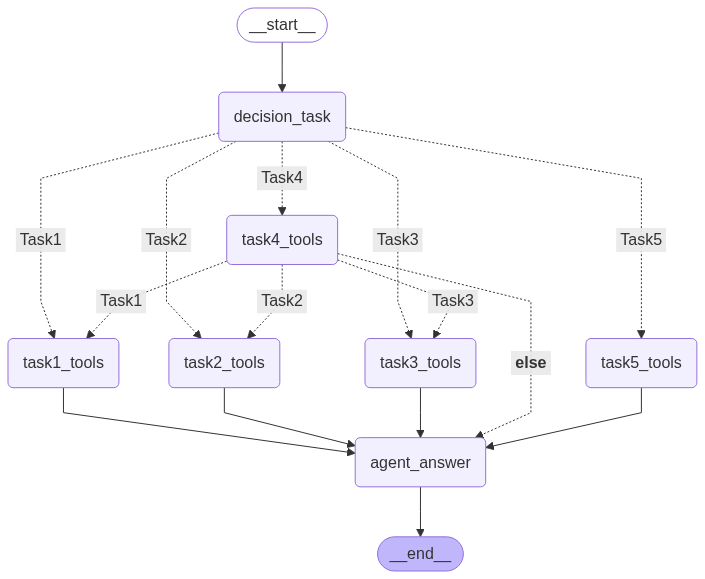

In [19]:
def route_tools(state: ChatbotState):
    return state["decision_task"]

builder = StateGraph(ChatbotState)

# 노드 추가
builder.add_node("decision_task", decision_task)
builder.add_node("task1_tools", task1_tools)
builder.add_node("task2_tools", task2_tools)
builder.add_node("task3_tools", task3_tools)
builder.add_node("task4_tools", task4_tools)
builder.add_node("task5_tools", task5_tools)
builder.add_node("agent_answer", agent_answer)

# 시작점 → decision_task
builder.add_edge(START, "decision_task")

# decision_task → 분기
builder.add_conditional_edges(
    "decision_task",
    route_tools,
    {
        "Task1": "task1_tools",
        "Task2": "task2_tools",
        "Task3": "task3_tools",
        "Task4": "task4_tools",
        "Task5": "task5_tools"
    }
)

# task1~3, task5는 바로 agent_answer로
builder.add_edge("task1_tools", "agent_answer")
builder.add_edge("task2_tools", "agent_answer")
builder.add_edge("task3_tools", "agent_answer")
builder.add_edge("task5_tools", "agent_answer")

# task4는 내부 판단 후 → Task1~3 or agent_answer
builder.add_conditional_edges(
    "task4_tools",
    lambda state: state["redirect_task"] if state.get("redirect_task") else "__else__",
    {
        "Task1": "task1_tools",
        "Task2": "task2_tools",
        "Task3": "task3_tools",
        "__else__": "agent_answer"
    }
)


# 종료
builder.add_edge("agent_answer", END)

# 컴파일
builder.compile(checkpointer=memory)

In [20]:
# Jupyter 노트북에서 실행할 셀들

# ============================================================================
# 1. Task4 테스트 실행
# ============================================================================

async def test_task4():
    """Task4 기능을 테스트하는 함수"""
    config = RunnableConfig(configurable={"thread_id": 4}) # 실행 환경 설정
    graph = builder.compile(checkpointer=memory) 
    
    # 모호한 질문 테스트
    test_cases = [
      # 1. 시간 기준 모호성 (시간점 불명)

        "수익봤으면 언제 팔아야돼?",
        "최근 많이 오른 주식을 알려줘",
        "고점 대비 많이 떨어진 주식을 보여줘",
        "요즘 급등한 종목이 뭐야?",
    #     "근래에 좋은 실적 발표한 회사 어디야?",
    #     "얼마전에 터진 악재 종목 알려줘",
    #     "올해 들어 많이 상승한 주식은?",
    #     "최근 급락한 종목을 찾아줘",
    #     "지금까지 수익률이 좋았던 주식은?",
    #     "작년 대비 많이 오른 종목 추천해줘",

    #     #2. 정량 기준 모호성 (수치/비율 불명)

    #     "상승률이 높은 주식을 보여줘",
    #     "거래량이 급증한 종목 알려줘",
    #     "PER이 낮은 저평가 주식 추천해줘",
    #     "배당률이 좋은 종목이 뭐야?",
    #     "시가총액이 큰 대형주를 알려줘",
    #     "변동성이 큰 종목 찾아줘",
    #     "수익률이 높은 펀드 추천해줘",
    #     "손실 폭이 큰 종목을 보여줘",
    #     "거래대금이 많은 인기 종목은?",
    #     "부채비율이 낮은 안전한 주식은?"
    ]
    
    
    for question in test_cases:
        print(f"\n{'='*50}")
        print(f"질문: {question}")
        print('='*50)
        
        # Chatstate 초기화 
        initial_state = { 
            "question": question,
            "decision_task": "",
            "tools": [],
            "tools_response": "",
            "task2_response": {},
            "task4_response": "",
            "answer": "", # 최종 답변
            "messages": [], # 멀티턴 대화를 위한 message 히스토리
        }
        
        events = [] # Agent 실행과정에서의 중간 이벤트 저장
        async for event in graph.astream(initial_state, config=config):
            events.append(event)
            
        # 결과 출력
        for event in events:
            if "decision_task" in event:
                print(f"🔍 분류: {event['decision_task']['decision_task']}")
            elif "agent_answer" in event and "answer" in event["agent_answer"]:
                print(f"💬 답변:\n{event['agent_answer']['answer']}")

# 실행
await test_task4()


질문: 수익봤으면 언제 팔아야돼?
🔍 분류: Task4
💬 답변:
수익 실현 시점을 결정하는 것은 개인의 투자 목표와 전략에 따라 다를 수 있습니다. 몇 가지 고려 사항을 제안드리겠습니다:

1. **목표 수익률**: 사전에 설정한 목표 수익률을 달성했을 때 매도할지 결정할 수 있습니다.
2. **특정 기간**: 예를 들어, 최근 한 달간 수익을 봤다면 그 기간에 맞춰 매도 타이밍을 잡을 수도 있습니다.
3. **시장 상황**: 현재 시장 상황을 고려해 매도 여부를 판단할 수 있습니다.

위의 세 가지 기준 중에서 어떤 것을 기준으로 삼고 싶으신지 알려주시면 좀 더 구체적으로 도와드릴 수 있습니다.

1. 특정 기간 내에서의 수익 실현 시점
2. 목표 수익률 도달 시 매도 여부
3. 기타 다른 기준

어떤 기준을 원하시나요? 더 궁금하신가요?

질문: 최근 많이 오른 주식을 알려줘
🔍 분류: Task4
💬 답변:
"최근"이라는 기간을 명확히 하기 위해 몇 가지 옵션을 제공해드리겠습니다.

1. 최근 30일 동안의 상승률
2. 최근 3개월(90일) 동안의 상승률
3. 올해 초부터 현재까지의 연간 상승률

어떤 기간의 데이터를 원하시나요? 또한 특정 시장(예: 코스피, 코스닥)이나 업종도 지정하실 수 있습니다. 이 정보를 바탕으로 가장 많이 오른 주식 목록을 제공해 드리겠습니다.

더 궁금하신가요? [redirect: Task1]

질문: 고점 대비 많이 떨어진 주식을 보여줘
🔍 분류: Task4
💬 답변:
고점 대비 얼마나 떨어졌는지 기간을 정해주셔야 정확한 데이터를 제공해드릴 수 있습니다. 예를 들어, 최근 30일 동안 고점 대비 많이 하락한 주식을 찾고 싶으신지, 아니면 지난 1년 동안의 데이터를 원하시는지요? 또한 특정 시장이나 업종에 국한된 정보를 원하시는지도 알려주시면 도움이 됩니다.

1. 최근 30일 간 고점 대비 많이 떨어진 주식
2. 지난 1년 간 고점 대비 많이 떨어진 주식
3. 특정 업종 내에서의 비교

위의 옵션 중에서 원하시는 것을 선택

In [ ]:
# ============================================================================
# 3. 단일 질문 테스트 함수
# ============================================================================

async def test_single_question(question: str):
    """단일 질문을 테스트하는 함수"""
    config = RunnableConfig(configurable={"thread_id": 1})
    graph = builder.compile(checkpointer=memory)
    
    print(f"질문: {question}")
    print('='*50)
    
    initial_state = {
        "question": question,
        "decision_task": "",
        "tools": [],
        "tools_response": "",
        "task2_response": {},
        "task4_response": "",
        
        "messages": [],
    }
    
    events = []
    async for event in graph.astream(initial_state, config=config):
        events.append(event)
        
    # 결과 출력
    for event in events:
        if "decision_task" in event:
            print(f"🔍 분류: {event['decision_task']['decision_task']}")
        elif "agent_answer" in event and "answer" in event["agent_answer"]:
            print(f"💬 답변:\n{event['agent_answer']['answer']}")


await test_single_question("고점 대비 떨어진 주식을 보여줘")


질문: 고점 대비 떨어진 주식을 보여줘
🔍 분류: Task4
💬 답변:
고점 대비 떨어진 주식을 확인하기 위해서는 특정 기간의 정보가 필요합니다. 아래에서 원하는 기간을 선택해 주세요:

1. 최근 1주일 (7일)
2. 최근 1개월 (30일)
3. 최근 3개월 (90일)
4. 최근 6개월 (180일)
5. 최근 1년 (252일)

또는 "YYYY-MM-DD부터 YYYY-MM-DD까지" 형식으로 직접 기간을 지정할 수도 있습니다.

예시: "최근 30일간 고점 대비 하락한 주식을 보여줘" 또는 "2024-01-01부터 2024-06-30까지 고점에서 가장 많이 떨어진 주식"

원하는 기간을 말씀해주시면 해당 조건에 맞는 주식 목록을 제공해드리겠습니다. 더 궁금하신가요?


In [ ]:
config = RunnableConfig(configurable={"thread_id": 1})

question = "2025-06-27에서 KOSPI에서 거래량 많은 종목 10개는?"

graph = builder.compile(checkpointer=memory)

initial_state = {
    "question": question,
    "decision_task":"",
    "tools": [],
    "tools_response" : [],
    "task2_response " : {},
    "answer": "",
    "messages": [],
} 

events = []
async for event in graph.astream(initial_state,config=config):
    print(event)
    events.append(event)

{'decision_task': {'decision_task': 'Task1'}}


/mnt/c/Users/rladl/Desktop/Mirae_Agent/MIRAE_ASSET_AI-Festival/sasha/test/task1_tools.py:97: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(

6 Failed downloads:
['139050.KQ', '226360.KQ', '111870.KQ']: YFPricesMissingError('possibly delisted; no price data found  (1d 2025-06-27 -> 2025-06-28)')
['415640.KQ', '499790.KQ', '487570.KQ']: YFTzMissingError('possibly delisted; no timezone found')
/mnt/c/Users/rladl/Desktop/Mirae_Agent/MIRAE_ASSET_AI-Festival/sasha/test/task1_tools.py:97: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(

2 Failed downloads:
['100090.KQ']: YFTzMissingError('possibly delisted; no timezone found')
['950110.KQ']: YFPricesMissingError('possibly delisted; no price data found  (1d 2025-06-27 -> 2025-06-28)')
/mnt/c/Users/rladl/Desktop/Mirae_Agent/MIRAE_ASSET_AI-Festival/sasha/test/task1_tools.py:97: FutureWarning: YF.download() has changed argument auto_adjust default